In [7]:
import pandas as pd

df = pd.read_csv(
    "data/train_ver2.csv.zip",
    compression="zip",
    nrows=10000,
    low_memory=False
)

display(df.head())

,fecha_dato,ncodpers,ind_empleado,pais_residencia,sexo,age,fecha_alta,ind_nuevo,antiguedad,indrel,...,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1375586,N,ES,H,35,2015-01-12,0.0,6,1.0,...,0,0,0,0,0,0,0,0.0,0.0,0
1,2015-01-28,1050611,N,ES,V,23,2012-08-10,0.0,35,1.0,...,0,0,0,0,0,0,0,0.0,0.0,0
2,2015-01-28,1050612,N,ES,V,23,2012-08-10,0.0,35,1.0,...,0,0,0,0,0,0,0,0.0,0.0,0
3,2015-01-28,1050613,N,ES,H,22,2012-08-10,0.0,35,1.0,...,0,0,0,0,0,0,0,0.0,0.0,0
4,2015-01-28,1050614,N,ES,V,23,2012-08-10,0.0,35,1.0,...,0,0,0,0,0,0,0,0.0,0.0,0


In [6]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
print("Nombre de clients :", df["ncodpers"].nunique())

Nombre de lignes : 10000
Nombre de colonnes : 48
Nombre de clients : 10000


In [8]:
print("Dates présentes dans l'échantillon :")
print(df["fecha_dato"].value_counts().sort_index())

print("\nNombre de mois distincts :")
print(df["fecha_dato"].nunique())

Dates présentes dans l'échantillon :
fecha_dato
2015-01-28    10000
Name: count, dtype: int64

Nombre de mois distincts :
1


In [9]:
produits = [
    col for col in df.columns
    if col.endswith("_ult1")
]

print("Nombre de produits :", len(produits))

for i, produit in enumerate(produits, start=1):
    print(i, produit)

Nombre de produits : 24
1 ind_ahor_fin_ult1
2 ind_aval_fin_ult1
3 ind_cco_fin_ult1
4 ind_cder_fin_ult1
5 ind_cno_fin_ult1
6 ind_ctju_fin_ult1
7 ind_ctma_fin_ult1
8 ind_ctop_fin_ult1
9 ind_ctpp_fin_ult1
10 ind_deco_fin_ult1
11 ind_deme_fin_ult1
12 ind_dela_fin_ult1
13 ind_ecue_fin_ult1
14 ind_fond_fin_ult1
15 ind_hip_fin_ult1
16 ind_plan_fin_ult1
17 ind_pres_fin_ult1
18 ind_reca_fin_ult1
19 ind_tjcr_fin_ult1
20 ind_valo_fin_ult1
21 ind_viv_fin_ult1
22 ind_nomina_ult1
23 ind_nom_pens_ult1
24 ind_recibo_ult1


In [10]:
# Conversion des indicateurs en valeurs numériques
df[produits] = df[produits].apply(
    pd.to_numeric, errors="coerce"
)

# Nombre de clients possédant chaque produit
effectifs = df[produits].sum()

# Nombre de clients dont la détention est connue
observations_valides = df[produits].notna().sum()

# Pourcentage parmi les observations valides
pourcentages = (
    effectifs / observations_valides * 100
)

# Tableau récapitulatif
stat_produits = pd.DataFrame({
    "Nombre de clients": effectifs,
    "Pourcentage (%)": pourcentages
})

stat_produits = stat_produits.sort_values(
    by="Nombre de clients",
    ascending=False
)

display(stat_produits)

,Nombre de clients,Pourcentage (%)
ind_cco_fin_ult1,9296.0,92.960000
ind_recibo_ult1,796.0,7.960000
ind_ecue_fin_ult1,633.0,6.330000
ind_cno_fin_ult1,369.0,3.690000
ind_nom_pens_ult1,240.0,2.402643
ind_nomina_ult1,218.0,2.182401
ind_tjcr_fin_ult1,109.0,1.090000
ind_reca_fin_ult1,106.0,1.060000
ind_dela_fin_ult1,85.0,0.850000
ind_ctju_fin_ult1,67.0,0.670000


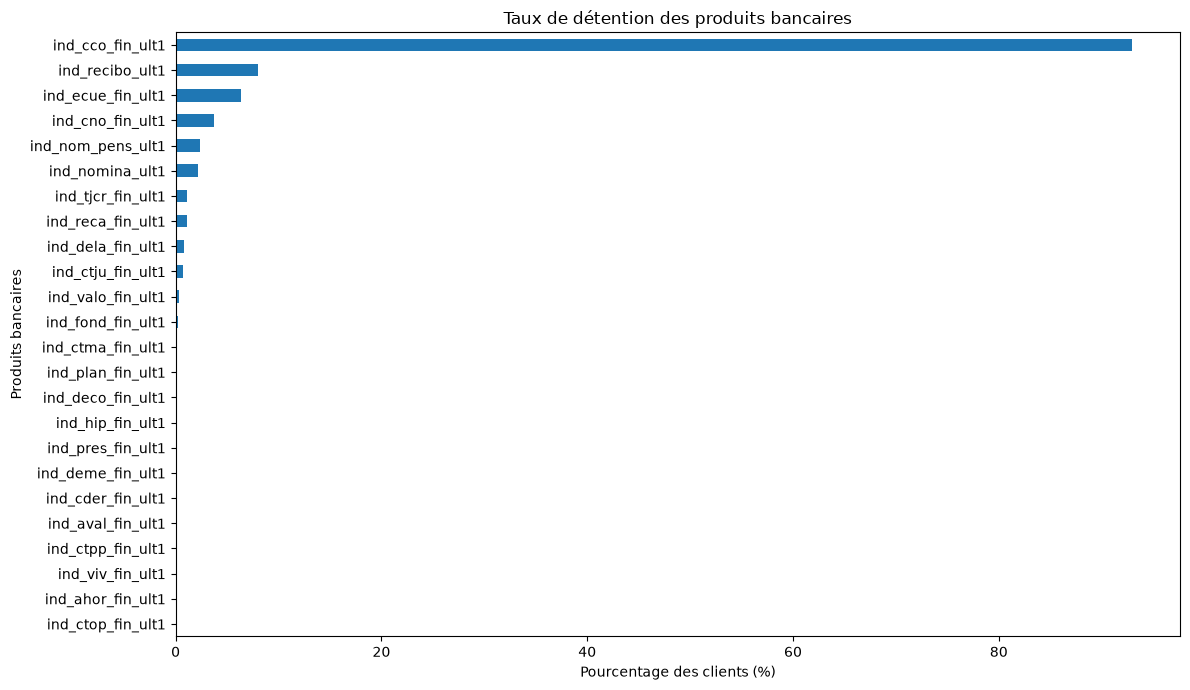

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

stat_produits["Pourcentage (%)"].sort_values().plot(
    kind="barh"
)

plt.title("Taux de détention des produits bancaires")
plt.xlabel("Pourcentage des clients (%)")
plt.ylabel("Produits bancaires")

plt.tight_layout()
plt.show()

In [14]:
print(df["ind_viv_fin_ult1"].value_counts(dropna=False))

print(
    "Valeurs manquantes :",
    df["ind_viv_fin_ult1"].isna().sum()
)

ind_viv_fin_ult1
0    10000
Name: count, dtype: int64
Valeurs manquantes : 0
